# Multi-Model T5 & Flan-T5 Seq2Seq Fine-Tuning Benchmark on Banking77
## Special Topics in Natural Language Processing (CSAI8333) — Fall 2026
### Unified Official Split Benchmark (Full Train / Official Test): **Awais M. Lodhi** (Seed: `42`)

* **Executor:** **Awais M. Lodhi** (ID: `L1F26PHDC0006`)
* **Random Reproducibility Seed:** `42`
* **Dataset:** Banking77 (`PolyAI-LDN/banking77`) — **Official Train/Test Split (No Validation Split)**
  * **Training Queries:** **10,003** instances (complete official `train.csv`)
  * **Test Queries:** **3,080** instances (complete official `test.csv`)
  * **Taxonomy:** 77 fine-grained customer intent categories (Seq2Seq generative text-to-text classification)
* **Models Benchmarked (7 Seq2Seq Architectures):**
  1. `t5-small` (~60M params — baseline vanilla T5)
  2. `t5-base` (~220M params — vanilla T5 Base)
  3. `t5-large` (~770M params — vanilla T5 Large, Adafactor + Gradient Checkpointing)
  4. `google/flan-t5-small` (~80M params — instruction-tuned Small)
  5. `google/flan-t5-base` (~250M params — instruction-tuned Base)
  6. `google/flan-t5-large` (~780M params — instruction-tuned Large, Adafactor + Gradient Checkpointing)
  7. `google/t5-v1_1-base` (~250M params — GEGLU architectural bridge between T5 and Flan-T5)

> **2-Tier Fault-Tolerant Resumption (Colab Disconnect Safe):**
> 1. **Model-Level Resume:** Any finished model (`metrics.json` exists) is automatically skipped and reloaded into the global CSV.
> 2. **Epoch-Level & Pre-Eval Resume:** Saves `pre_metrics.json` after zero-shot evaluation and overwrites a `resume_checkpoint/` folder (model weights, optimizer, scheduler, elapsed training time) after every epoch. If Colab disconnects mid-model, re-running picks up directly at the next unfinished epoch, then removes `resume_checkpoint/` once finalized to save Drive storage.

In [ ]:
# --- 1. Install Required Packages ---
!pip install -q transformers datasets scikit-learn accelerate sentencepiece protobuf pandas matplotlib seaborn tabulate

In [ ]:
# --- 2. Environment Detection & Storage Directory Setup ---
import os
import shutil

ASSIGNED_SEED = 42
COLAB_STORAGE_FOLDER = "T5_training_Awais_Seed42"

def detect_environment_and_setup_storage():
    is_colab = False
    try:
        import google.colab
        is_colab = True
    except ImportError:
        is_colab = False

    if is_colab:
        print("[ENVIRONMENT] Detected Google Colab environment.")
        try:
            from google.colab import drive
            if not os.path.exists("/content/drive/MyDrive"):
                print("[STORAGE] Mounting Google Drive at /content/drive...")
                drive.mount("/content/drive")
            base_dir = f"/content/drive/MyDrive/NLP_Checkpoints/{COLAB_STORAGE_FOLDER}"
            os.makedirs(base_dir, exist_ok=True)
            print(f"[STORAGE] Checkpoints & results will be saved to Google Drive:\n   -> {base_dir}")
            return "colab", base_dir
        except Exception as e:
            print(f"[STORAGE WARNING] Google Drive mount failed ({e}). Saving locally.")
            base_dir = os.path.abspath(f"./{COLAB_STORAGE_FOLDER}")
            os.makedirs(base_dir, exist_ok=True)
            return "local", base_dir
    else:
        print("[ENVIRONMENT] Detected Local Execution environment.")
        base_dir = os.path.abspath(f"./{COLAB_STORAGE_FOLDER}")
        os.makedirs(base_dir, exist_ok=True)
        print(f"[STORAGE] Checkpoints & results will be saved locally:\n   -> {base_dir}")
        return "local", base_dir

ENV_TYPE, BASE_OUTPUT_DIR = detect_environment_and_setup_storage()

[ENVIRONMENT] Detected Google Colab environment.
[STORAGE] Mounting Google Drive at /content/drive...
Mounted at /content/drive
[STORAGE] Checkpoints & results will be saved to Google Drive:
   -> /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42


In [ ]:
# --- 3. Import Libraries, Precision Check & Seed Configuration ---
import gc
import re
import csv
import json
import time
import random
import difflib
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Adafactor,
    get_linear_schedule_with_warmup
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(ASSIGNED_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported())
print(f"[PYTORCH] Compute Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"[PRECISION] Using {'bfloat16 (Ampere+)' if USE_BF16 else 'float32 (safe for T5/Flan-T5 on T4)'}")
print(f"[SEED] Global reproducibility seed locked to: {ASSIGNED_SEED}")

[PYTORCH] Compute Device: cuda
   GPU Model: Tesla T4
   VRAM: 15.64 GB
[PRECISION] Using bfloat16 (Ampere+)
[SEED] Global reproducibility seed locked to: 42


In [ ]:
# --- 4. Load Official Full Banking77 Dataset (Train: 10,003 | Test: 3,080 | No Validation Split) ---
BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

label2id = {name: i for i, name in enumerate(BANKING77_LABELS)}
id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
num_classes = len(BANKING77_LABELS)

def load_official_banking77():
    """
    Loads the FULL official PolyAI Banking77 splits with NO validation slice:
      - Train: 10,003 queries
      - Test:  3,080 queries
    """
    cache_dir = "./data/banking77_official"
    tr_cache = os.path.join(cache_dir, "train.csv")
    te_cache = os.path.join(cache_dir, "test.csv")

    def read_csv_file(path):
        texts, labels = [], []
        with open(path, encoding="utf-8") as f:
            for row in csv.DictReader(f):
                texts.append(row["text"])
                cat = row.get("category") or row.get("label")
                labels.append(label2id[cat] if cat in label2id else int(cat))
        return texts, labels

    if os.path.exists(tr_cache) and os.path.exists(te_cache):
        tr_t, tr_l = read_csv_file(tr_cache)
        te_t, te_l = read_csv_file(te_cache)
        if len(tr_t) == 10003 and len(te_t) == 3080:
            print(f"[DATASET] Loaded cached official splits from {cache_dir}.")
            return tr_t, tr_l, te_t, te_l

    print("[DATASET] Downloading canonical official splits from PolyAI GitHub repository...")
    os.makedirs(cache_dir, exist_ok=True)
    urls = {
        tr_cache: "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv",
        te_cache: "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv",
    }
    for dst, url in urls.items():
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(dst, "wb") as out_f:
            out_f.write(resp.read())

    tr_t, tr_l = read_csv_file(tr_cache)
    te_t, te_l = read_csv_file(te_cache)
    assert len(tr_t) == 10003, f"Expected 10,003 official train queries, got {len(tr_t)}"
    assert len(te_t) == 3080, f"Expected 3,080 official test queries, got {len(te_t)}"
    return tr_t, tr_l, te_t, te_l

train_texts, train_labels, test_texts, test_labels = load_official_banking77()
print(f"Dataset verified -> Train: {len(train_texts):,} | Test: {len(test_texts):,} | Classes: {num_classes} | Val: None (Full Official Train)")

[DATASET] Downloading canonical official splits from PolyAI GitHub repository...
Dataset verified -> Train: 10,003 | Test: 3,080 | Classes: 77 | Val: None (Full Official Train)


In [ ]:
# --- 5. Seq2Seq Dataset Wrapper & Label Parsing Utilities ---
MAX_SOURCE_LENGTH = 64
MAX_TARGET_LENGTH = 24  # Safely covers longest Banking77 class string (up to ~18 tokens)
TASK_PREFIX = "classify banking intent: "

class T5IntentDataset(Dataset):
    def __init__(self, texts, label_ids, tokenizer, max_src_len=64, max_tgt_len=24):
        self.prompts = [TASK_PREFIX + t.strip() for t in texts]
        self.label_ids = label_ids
        self.target_texts = [id2label[lid] for lid in label_ids]
        self.tokenizer = tokenizer

        self.src_enc = tokenizer(
            self.prompts,
            padding="max_length",
            truncation=True,
            max_length=max_src_len,
            return_tensors="pt"
        )
        self.tgt_enc = tokenizer(
            self.target_texts,
            padding="max_length",
            truncation=True,
            max_length=max_tgt_len,
            return_tensors="pt"
        )
        labels = self.tgt_enc["input_ids"].clone()
        labels[labels == tokenizer.pad_token_id] = -100  # Mask padding from cross-entropy loss
        self.labels = labels

    def __len__(self):
        return len(self.label_ids)

    def __getitem__(self, idx):
        return {
            "input_ids": self.src_enc["input_ids"][idx],
            "attention_mask": self.src_enc["attention_mask"][idx],
            "labels": self.labels[idx],
            "label_id": self.label_ids[idx],
        }

LOWER_LABEL_MAP = {lbl.lower(): i for i, lbl in enumerate(BANKING77_LABELS)}

def parse_seq2seq_prediction(gen_text):
    """Maps generated Seq2Seq string to canonical Banking77 label ID, tracking exact vs fuzzy matches."""
    clean = gen_text.strip().strip('"').strip("'").strip()
    clean_lower = clean.lower()

    if clean_lower in LOWER_LABEL_MAP:
        return LOWER_LABEL_MAP[clean_lower], True

    for lbl in sorted(BANKING77_LABELS, key=len, reverse=True):
        if re.search(r"\b" + re.escape(lbl.lower()) + r"\b", clean_lower):
            return label2id[lbl], False

    close = difflib.get_close_matches(clean_lower, list(LOWER_LABEL_MAP.keys()), n=1, cutoff=0.6)
    if close:
        return LOWER_LABEL_MAP[close[0]], False

    return -1, False

def evaluate_seq2seq(model, dataloader, tokenizer, device, desc="Evaluating"):
    model.eval()
    preds, trues = [], []
    raw_texts = []
    exact_matches = 0
    unmapped_count = 0

    t0 = time.time()
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=desc, leave=False):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            if USE_BF16:
                with torch.amp.autocast("cuda", dtype=torch.bfloat16):
                    gen_ids = model.generate(
                        input_ids=input_ids,
                        attention_mask=attention_mask,
                        max_new_tokens=MAX_TARGET_LENGTH,
                        num_beams=1,
                        do_sample=False
                    )
            else:
                gen_ids = model.generate(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    max_new_tokens=MAX_TARGET_LENGTH,
                    num_beams=1,
                    do_sample=False
                )

            decoded = tokenizer.batch_decode(gen_ids, skip_special_tokens=True)
            for g_txt, true_id in zip(decoded, batch["label_id"].tolist()):
                pred_id, is_exact = parse_seq2seq_prediction(g_txt)
                if is_exact:
                    exact_matches += 1
                if pred_id == -1:
                    unmapped_count += 1
                preds.append(pred_id)
                trues.append(true_id)
                raw_texts.append(g_txt.strip())

    eval_seconds = time.time() - t0
    latency_ms = (eval_seconds / len(trues)) * 1000.0
    safe_preds = [p if p != -1 else ((t + 1) % num_classes) for p, t in zip(preds, trues)]

    metrics = {
        "accuracy": accuracy_score(trues, safe_preds),
        "precision_weighted": precision_score(trues, safe_preds, average="weighted", zero_division=0),
        "precision_macro": precision_score(trues, safe_preds, average="macro", zero_division=0),
        "recall_weighted": recall_score(trues, safe_preds, average="weighted", zero_division=0),
        "recall_macro": recall_score(trues, safe_preds, average="macro", zero_division=0),
        "f1_weighted": f1_score(trues, safe_preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(trues, safe_preds, average="macro", zero_division=0),
        "exact_match_rate": exact_matches / len(trues),
        "unmapped_rate": unmapped_count / len(trues),
        "eval_time_seconds": eval_seconds,
        "latency_ms_per_query": latency_ms,
    }
    return metrics, trues, preds, raw_texts

In [ ]:
# --- 6. Model Registry (7 T5 / Flan-T5 Seq2Seq Architectures) ---
# Epoch & Optimizer choices tailored for 10,003 Banking77 queries on 15 GB Colab T4:
#   - Small/Base: 5 epochs (~1,565 steps at effective BS=32), AdamW
#   - Large (~770M): 4 epochs (~1,252 steps), Adafactor + Gradient Checkpointing to stay safely < 11 GB VRAM

ALL_MODELS = [
    {
        "key": "t5-small",
        "name": "T5-Small",
        "save_dir_name": "T5-Small",
        "model_id": "t5-small",
        "epochs": 5,
        "batch_size": 32,
        "eval_batch_size": 64,
        "grad_accum": 1,
        "lr": 3e-4,
        "optimizer": "adamw",
        "grad_checkpointing": False,
    },
    {
        "key": "t5-base",
        "name": "T5-Base",
        "save_dir_name": "T5-Base",
        "model_id": "t5-base",
        "epochs": 5,
        "batch_size": 16,
        "eval_batch_size": 32,
        "grad_accum": 2,
        "lr": 3e-4,
        "optimizer": "adamw",
        "grad_checkpointing": False,
    },
    {
        "key": "t5-large",
        "name": "T5-Large",
        "save_dir_name": "T5-Large",
        "model_id": "t5-large",
        "epochs": 4,
        "batch_size": 8,
        "eval_batch_size": 16,
        "grad_accum": 4,
        "lr": 1e-4,
        "optimizer": "adafactor",
        "grad_checkpointing": True,
    },
    {
        "key": "flan-t5-small",
        "name": "Flan-T5-Small",
        "save_dir_name": "Flan-T5-Small",
        "model_id": "google/flan-t5-small",
        "epochs": 5,
        "batch_size": 32,
        "eval_batch_size": 64,
        "grad_accum": 1,
        "lr": 3e-4,
        "optimizer": "adamw",
        "grad_checkpointing": False,
    },
    {
        "key": "flan-t5-base",
        "name": "Flan-T5-Base",
        "save_dir_name": "Flan-T5-Base",
        "model_id": "google/flan-t5-base",
        "epochs": 5,
        "batch_size": 16,
        "eval_batch_size": 32,
        "grad_accum": 2,
        "lr": 2e-4,
        "optimizer": "adamw",
        "grad_checkpointing": False,
    },
    {
        "key": "flan-t5-large",
        "name": "Flan-T5-Large",
        "save_dir_name": "Flan-T5-Large",
        "model_id": "google/flan-t5-large",
        "epochs": 4,
        "batch_size": 8,
        "eval_batch_size": 16,
        "grad_accum": 4,
        "lr": 1e-4,
        "optimizer": "adafactor",
        "grad_checkpointing": True,
    },
    {
        "key": "t5-v1_1-base",
        "name": "T5-v1.1-Base",
        "save_dir_name": "T5-v1_1-Base",
        "model_id": "google/t5-v1_1-base",
        "epochs": 5,
        "batch_size": 16,
        "eval_batch_size": 32,
        "grad_accum": 2,
        "lr": 3e-4,
        "optimizer": "adamw",
        "grad_checkpointing": False,
    },
]

MODELS_TO_RUN = ALL_MODELS

SAMPLE_QUERIES = [
    "How long does it take to get my new debit card in the mail?",
    "I tried to pay at the grocery store and my card got declined.",
    "Why was I charged an extra fee for transferring money abroad?",
    "My phone was stolen and my banking app is logged in on it.",
    "Can I top up my account using an American Express card?"
]

print(f"Configured {len(MODELS_TO_RUN)} Seq2Seq architectures for Banking77 benchmark:")
for i, m in enumerate(MODELS_TO_RUN, 1):
    print(f"  {i}. {m['name']:<16} ({m['model_id']:<24}) | epochs={m['epochs']}, bs={m['batch_size']}x{m['grad_accum']}, optim={m['optimizer']}")

Configured 7 Seq2Seq architectures for Banking77 benchmark:
  1. T5-Small         (t5-small                ) | epochs=5, bs=32x1, optim=adamw
  2. T5-Base          (t5-base                 ) | epochs=5, bs=16x2, optim=adamw
  3. T5-Large         (t5-large                ) | epochs=4, bs=8x4, optim=adafactor
  4. Flan-T5-Small    (google/flan-t5-small    ) | epochs=5, bs=32x1, optim=adamw
  5. Flan-T5-Base     (google/flan-t5-base     ) | epochs=5, bs=16x2, optim=adamw
  6. Flan-T5-Large    (google/flan-t5-large    ) | epochs=4, bs=8x4, optim=adafactor
  7. T5-v1.1-Base     (google/t5-v1_1-base     ) | epochs=5, bs=16x2, optim=adamw


In [ ]:
# --- 7. Fault-Tolerant Master Benchmark Loop (2-Tier Resume: Model + Epoch) ---
results_records = []
output_csv_path = os.path.join(BASE_OUTPUT_DIR, "banking77_t5_benchmark_results.csv")

for model_idx, cfg in enumerate(MODELS_TO_RUN, 1):
    model_name = cfg["name"]
    save_dir_name = cfg["save_dir_name"]
    model_id = cfg["model_id"]
    epochs = cfg["epochs"]
    batch_size = cfg["batch_size"]
    eval_bs = cfg["eval_batch_size"]
    grad_accum = cfg["grad_accum"]
    lr = cfg["lr"]
    optim_type = cfg["optimizer"]
    use_grad_ckpt = cfg["grad_checkpointing"]

    model_output_dir = os.path.join(BASE_OUTPUT_DIR, save_dir_name)
    os.makedirs(model_output_dir, exist_ok=True)
    metrics_file = os.path.join(model_output_dir, "metrics.json")
    pre_metrics_file = os.path.join(model_output_dir, "pre_metrics.json")
    resume_dir = os.path.join(model_output_dir, "resume_checkpoint")
    state_pt = os.path.join(resume_dir, "training_state.pt")

    # ---------------------------------------------------------
    # TIER 1 RESUME: Skip fully completed models
    # ---------------------------------------------------------
    if os.path.exists(metrics_file):
        print("=" * 85)
        print(f"[{model_idx}/{len(MODELS_TO_RUN)}] CACHED: {model_name} ({model_id})")
        print(f"   Loading existing metrics from {metrics_file}...")
        print("=" * 85)
        with open(metrics_file, "r") as f:
            saved_summary = json.load(f)
        pre_m = saved_summary["pre_metrics"]
        post_m = saved_summary["post_metrics"]
        deltas = saved_summary.get("deltas", {})
        results_records.append({
            "Model Name": model_name,
            "Model ID": model_id,
            "Save Directory": model_output_dir,
            "Pre-Train Accuracy (%)": round(pre_m["accuracy"] * 100, 2),
            "Post-Train Accuracy (%)": round(post_m["accuracy"] * 100, 2),
            "Accuracy Gain (%)": deltas.get("accuracy_gain_pct", round((post_m["accuracy"] - pre_m["accuracy"]) * 100, 2)),
            "Pre-Train Macro F1 (%)": round(pre_m["f1_macro"] * 100, 2),
            "Post-Train Macro F1 (%)": round(post_m["f1_macro"] * 100, 2),
            "Macro F1 Gain (%)": deltas.get("macro_f1_gain_pct", round((post_m["f1_macro"] - pre_m["f1_macro"]) * 100, 2)),
            "Post-Train Weighted F1 (%)": round(post_m["f1_weighted"] * 100, 2),
            "Post-Train Macro Precision (%)": round(post_m["precision_macro"] * 100, 2),
            "Post-Train Macro Recall (%)": round(post_m["recall_macro"] * 100, 2),
            "Exact Match Rate (%)": round(post_m["exact_match_rate"] * 100, 2),
            "Unmapped Rate (%)": round(post_m["unmapped_rate"] * 100, 2),
            "Inference Latency (ms/query)": round(post_m["latency_ms_per_query"], 2),
            "Training Time (min)": saved_summary.get("training_time_minutes", 0.0),
            "Wall Time (s)": saved_summary.get("wall_time_seconds", 0.0),
            "Peak VRAM Allocated (GB)": saved_summary.get("peak_vram_allocated_gb", 0.0),
            "Peak VRAM Reserved (GB)": saved_summary.get("peak_vram_reserved_gb", 0.0),
            "Epochs": saved_summary.get("epochs", epochs),
        })
        continue

    print("=" * 85)
    print(f"[{model_idx}/{len(MODELS_TO_RUN)}] PROCESSING: {model_name} ({model_id})")
    print(f"   Epochs: {epochs} | BS: {batch_size}x{grad_accum} | LR: {lr} | Optim: {optim_type} | GradCkpt: {use_grad_ckpt}")
    print("=" * 85)

    # Check Tier 2 Mid-Model Resume Checkpoint
    resuming = os.path.exists(state_pt) and os.path.exists(os.path.join(resume_dir, "config.json"))
    load_source = resume_dir if resuming else model_id

    set_seed(ASSIGNED_SEED)
    tokenizer = AutoTokenizer.from_pretrained(load_source)
    model = AutoModelForSeq2SeqLM.from_pretrained(load_source).float()
    if use_grad_ckpt:
        model.config.use_cache = False
        model.gradient_checkpointing_enable()
    model.to(device)

    train_dataset = T5IntentDataset(train_texts, train_labels, tokenizer, MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH)
    test_dataset = T5IntentDataset(test_texts, test_labels, tokenizer, MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=eval_bs, shuffle=False)

    # 1. Pre-Trained Evaluation (Cached so resumed runs skip repeating pre-eval)
    if os.path.exists(pre_metrics_file):
        with open(pre_metrics_file, "r") as pmf:
            pre_metrics = json.load(pmf)
        print(f"[PRE-EVAL CACHED] Pre-Train Acc: {pre_metrics['accuracy']*100:.2f}% | Macro F1: {pre_metrics['f1_macro']*100:.2f}%")
    else:
        print(f"[PRE-EVAL] Evaluating pre-trained {model_name} on {len(test_dataset):,} test queries...")
        pre_metrics, _, _, _ = evaluate_seq2seq(model, test_loader, tokenizer, device, desc="Pre-Eval")
        with open(pre_metrics_file, "w") as pmf:
            json.dump({k: float(v) for k, v in pre_metrics.items()}, pmf, indent=2)
        print(f"   Pre-Train Acc: {pre_metrics['accuracy']*100:.2f}% | Macro F1: {pre_metrics['f1_macro']*100:.2f}% | Unmapped: {pre_metrics['unmapped_rate']*100:.2f}%")

    # 2. Optimizer & Scheduler
    if optim_type == "adafactor":
        optimizer = Adafactor(
            model.parameters(),
            lr=lr,
            relative_step=False,
            scale_parameter=False,
            warmup_init=False,
            weight_decay=0.01
        )
    else:
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

    total_steps = (len(train_loader) // grad_accum) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.1),
        num_training_steps=max(total_steps, 1)
    )

    start_epoch = 0
    accumulated_train_time = 0.0
    prev_vram_alloc = 0.0
    prev_vram_res = 0.0

    if resuming:
        try:
            ckpt = torch.load(state_pt, map_location=device, weights_only=False)
        except TypeError:
            ckpt = torch.load(state_pt, map_location=device)
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        start_epoch = ckpt["completed_epoch"] + 1
        accumulated_train_time = ckpt.get("elapsed_train_seconds", 0.0)
        prev_vram_alloc = ckpt.get("peak_vram_allocated_gb", 0.0)
        prev_vram_res = ckpt.get("peak_vram_reserved_gb", 0.0)
        if "python_rng" in ckpt:
            random.setstate(ckpt["python_rng"])
            np.random.set_state(ckpt["numpy_rng"])
            torch.set_rng_state(ckpt["torch_rng"].cpu())
        print(f"[TIER-2 RESUME] Found epoch checkpoint! Resuming {model_name} at Epoch {start_epoch + 1}/{epochs} (prior time: {accumulated_train_time/60:.2f} min)...")

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(device)

    # 3. Full Fine-Tuning Loop with End-of-Epoch Checkpointing
    if start_epoch < epochs:
        print(f"[TRAIN] Fine-tuning {model_name} (Epochs {start_epoch + 1}..{epochs}) on {len(train_dataset):,} queries...")
    for epoch in range(start_epoch, epochs):
        ep_start = time.time()
        model.train()
        total_loss = 0.0
        optimizer.zero_grad()
        pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}/{epochs}")
        for step, batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            if USE_BF16:
                with torch.amp.autocast("cuda", dtype=torch.bfloat16):
                    outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                    loss = outputs.loss / grad_accum
            else:
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                loss = outputs.loss / grad_accum

            loss.backward()
            total_loss += loss.item() * grad_accum

            if (step + 1) % grad_accum == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            pbar.set_postfix({"loss": f"{total_loss / (step + 1):.4f}"})

        accumulated_train_time += (time.time() - ep_start)
        cur_vram_alloc = round(torch.cuda.max_memory_allocated(device) / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
        cur_vram_res = round(torch.cuda.max_memory_reserved(device) / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
        prev_vram_alloc = max(prev_vram_alloc, cur_vram_alloc)
        prev_vram_res = max(prev_vram_res, cur_vram_res)

        print(f"   Epoch {epoch+1}/{epochs} | Avg Train Loss: {total_loss / len(train_loader):.4f} | Saving resume checkpoint...")

        # Save overwriteable end-of-epoch checkpoint (only if more epochs remain)
        if epoch + 1 < epochs:
            os.makedirs(resume_dir, exist_ok=True)
            model.save_pretrained(resume_dir)
            tokenizer.save_pretrained(resume_dir)
            torch.save({
                "completed_epoch": epoch,
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "elapsed_train_seconds": accumulated_train_time,
                "peak_vram_allocated_gb": prev_vram_alloc,
                "peak_vram_reserved_gb": prev_vram_res,
                "python_rng": random.getstate(),
                "numpy_rng": np.random.get_state(),
                "torch_rng": torch.get_rng_state(),
            }, state_pt)

    train_duration = accumulated_train_time
    max_vram_alloc = prev_vram_alloc
    max_vram_res = prev_vram_res
    print(f"[COMPLETE] Finished in {train_duration/60:.2f} min | Peak VRAM: {max_vram_alloc} GB allocated / {max_vram_res} GB reserved")

    # 4. Post-Trained Evaluation on Official Test Set
    if use_grad_ckpt:
        model.gradient_checkpointing_disable()
        model.config.use_cache = True

    post_metrics, y_true, y_pred, raw_preds = evaluate_seq2seq(model, test_loader, tokenizer, device, desc="Post-Eval")
    print(f"   [Post-Train] Test Accuracy:   {post_metrics['accuracy']*100:.2f}% (Gain: +{(post_metrics['accuracy']-pre_metrics['accuracy'])*100:.2f}%)")
    print(f"   [Post-Train] Test Macro F1:   {post_metrics['f1_macro']*100:.2f}% | Exact Match: {post_metrics['exact_match_rate']*100:.2f}% | Latency: {post_metrics['latency_ms_per_query']:.2f} ms/query")

    # 5. Qualitative Sample Predictions
    print(f"\n[SAMPLES] Predictions from {model_name}:")
    sample_enc = tokenizer([TASK_PREFIX + q for q in SAMPLE_QUERIES], padding=True, truncation=True, max_length=MAX_SOURCE_LENGTH, return_tensors="pt").to(device)
    with torch.no_grad():
        sample_out = model.generate(**sample_enc, max_new_tokens=MAX_TARGET_LENGTH, num_beams=1)
    for q, gen_txt in zip(SAMPLE_QUERIES, tokenizer.batch_decode(sample_out, skip_special_tokens=True)):
        pid, _ = parse_seq2seq_prediction(gen_txt)
        lbl_str = id2label[pid] if pid != -1 else f"UNMAPPED({gen_txt})"
        print(f'   Query: "{q}" -> {lbl_str}')

    # 6. Save Final Model, Predictions & Metrics (and clean up temporary resume_checkpoint)
    model.save_pretrained(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)

    pred_records = [
        {
            "index": idx_q,
            "text": test_texts[idx_q],
            "true_id": int(t_id),
            "true_label": id2label[t_id],
            "pred_id": int(p_id),
            "pred_label": id2label[p_id] if p_id != -1 else "UNMAPPED",
            "raw_generated": r_txt,
        }
        for idx_q, (t_id, p_id, r_txt) in enumerate(zip(y_true, y_pred, raw_preds))
    ]
    with open(os.path.join(model_output_dir, "test_predictions.json"), "w") as pf:
        json.dump(pred_records, pf, indent=2)

    model_eval_summary = {
        "model_name": model_name,
        "model_id": model_id,
        "seed": ASSIGNED_SEED,
        "epochs": epochs,
        "optimizer": optim_type,
        "learning_rate": lr,
        "effective_batch_size": batch_size * grad_accum,
        "precision": "bf16" if USE_BF16 else "fp32",
        "training_time_minutes": round(train_duration / 60, 2),
        "wall_time_seconds": round(train_duration, 2),
        "peak_vram_allocated_gb": max_vram_alloc,
        "peak_vram_reserved_gb": max_vram_res,
        "dataset_split": {"train_samples": len(train_texts), "val_samples": 0, "test_samples": len(test_texts)},
        "pre_metrics": {k: float(v) for k, v in pre_metrics.items()},
        "post_metrics": {k: float(v) for k, v in post_metrics.items()},
        "deltas": {
            "accuracy_gain_pct": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
            "macro_f1_gain_pct": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        }
    }
    with open(metrics_file, "w") as f:
        json.dump(model_eval_summary, f, indent=2)

    if os.path.exists(resume_dir):
        shutil.rmtree(resume_dir, ignore_errors=True)
        print(f"[DISK CLEANUP] Removed temporary resume_checkpoint/ for {model_name} to save Drive quota.")

    results_records.append({
        "Model Name": model_name,
        "Model ID": model_id,
        "Save Directory": model_output_dir,
        "Pre-Train Accuracy (%)": round(pre_metrics["accuracy"] * 100, 2),
        "Post-Train Accuracy (%)": round(post_metrics["accuracy"] * 100, 2),
        "Accuracy Gain (%)": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
        "Pre-Train Macro F1 (%)": round(pre_metrics["f1_macro"] * 100, 2),
        "Post-Train Macro F1 (%)": round(post_metrics["f1_macro"] * 100, 2),
        "Macro F1 Gain (%)": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        "Post-Train Weighted F1 (%)": round(post_metrics["f1_weighted"] * 100, 2),
        "Post-Train Macro Precision (%)": round(post_metrics["precision_macro"] * 100, 2),
        "Post-Train Macro Recall (%)": round(post_metrics["recall_macro"] * 100, 2),
        "Exact Match Rate (%)": round(post_metrics["exact_match_rate"] * 100, 2),
        "Unmapped Rate (%)": round(post_metrics["unmapped_rate"] * 100, 2),
        "Inference Latency (ms/query)": round(post_metrics["latency_ms_per_query"], 2),
        "Training Time (min)": round(train_duration / 60, 2),
        "Wall Time (s)": round(train_duration, 2),
        "Peak VRAM Allocated (GB)": max_vram_alloc,
        "Peak VRAM Reserved (GB)": max_vram_res,
        "Epochs": epochs,
    })

    pd.DataFrame(results_records).to_csv(output_csv_path, index=False)
    print(f"[CHECKPOINT] Updated benchmark CSV: {output_csv_path}")

    del model, optimizer, scheduler, train_loader, test_loader, train_dataset, test_dataset, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nALL T5 / FLAN-T5 BENCHMARKS COMPLETED!")

[1/7] CACHED: T5-Small (t5-small)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/T5-Small/metrics.json...
[2/7] CACHED: T5-Base (t5-base)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/T5-Base/metrics.json...
[3/7] CACHED: T5-Large (t5-large)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/T5-Large/metrics.json...
[4/7] CACHED: Flan-T5-Small (google/flan-t5-small)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/Flan-T5-Small/metrics.json...
[5/7] CACHED: Flan-T5-Base (google/flan-t5-base)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/Flan-T5-Base/metrics.json...
[6/7] PROCESSING: Flan-T5-Large (google/flan-t5-large)
   Epochs: 4 | BS: 8x4 | LR: 0.0001 | Optim: adafactor | GradCkpt: True


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


[PRE-EVAL CACHED] Pre-Train Acc: 1.72% | Macro F1: 1.17%
[TIER-2 RESUME] Found epoch checkpoint! Resuming Flan-T5-Large at Epoch 3/4 (prior time: 48.85 min)...
[TRAIN] Fine-tuning Flan-T5-Large (Epochs 3..4) on 10,003 queries...


Epoch 3/4:   0%|          | 0/1251 [00:00<?, ?it/s]

   Epoch 3/4 | Avg Train Loss: 0.0429 | Saving resume checkpoint...


... (35 outputs left out)

Post-Eval:   0%|          | 0/97 [00:00<?, ?it/s]

   [Post-Train] Test Accuracy:   89.94% (Gain: +89.90%)
   [Post-Train] Test Macro F1:   89.97% | Exact Match: 99.97% | Latency: 17.33 ms/query

[SAMPLES] Predictions from T5-v1.1-Base:
   Query: "How long does it take to get my new debit card in the mail?" -> direct_debit_payment_not_recognised
   Query: "I tried to pay at the grocery store and my card got declined." -> declined_card_payment
   Query: "Why was I charged an extra fee for transferring money abroad?" -> transfer_fee_charged
   Query: "My phone was stolen and my banking app is logged in on it." -> lost_or_stolen_phone
   Query: "Can I top up my account using an American Express card?" -> supported_cards_and_currencies


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[DISK CLEANUP] Removed temporary resume_checkpoint/ for T5-v1.1-Base to save Drive quota.
[CHECKPOINT] Updated benchmark CSV: /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/banking77_t5_benchmark_results.csv

ALL T5 / FLAN-T5 BENCHMARKS COMPLETED!


FINAL BANKING77 T5 / FLAN-T5 BENCHMARK SUMMARY (Train: 10,003 | Test: 3,080)
| Model Name    |   Pre-Train Accuracy (%) |   Post-Train Accuracy (%) |   Accuracy Gain (%) |   Post-Train Macro F1 (%) |   Exact Match Rate (%) |   Inference Latency (ms/query) |   Training Time (min) |   Peak VRAM Allocated (GB) |   Epochs |
|:--------------|-------------------------:|--------------------------:|--------------------:|--------------------------:|-----------------------:|-------------------------------:|----------------------:|---------------------------:|---------:|
| T5-Small      |                     1.07 |                     88.6  |               87.53 |                     88.62 |                  99.81 |                           7.22 |                124.69 |                      1.828 |        5 |
| T5-Base       |                     1.46 |                     93.12 |               91.66 |                     93.15 |                  99.9  |                          19.29 |        

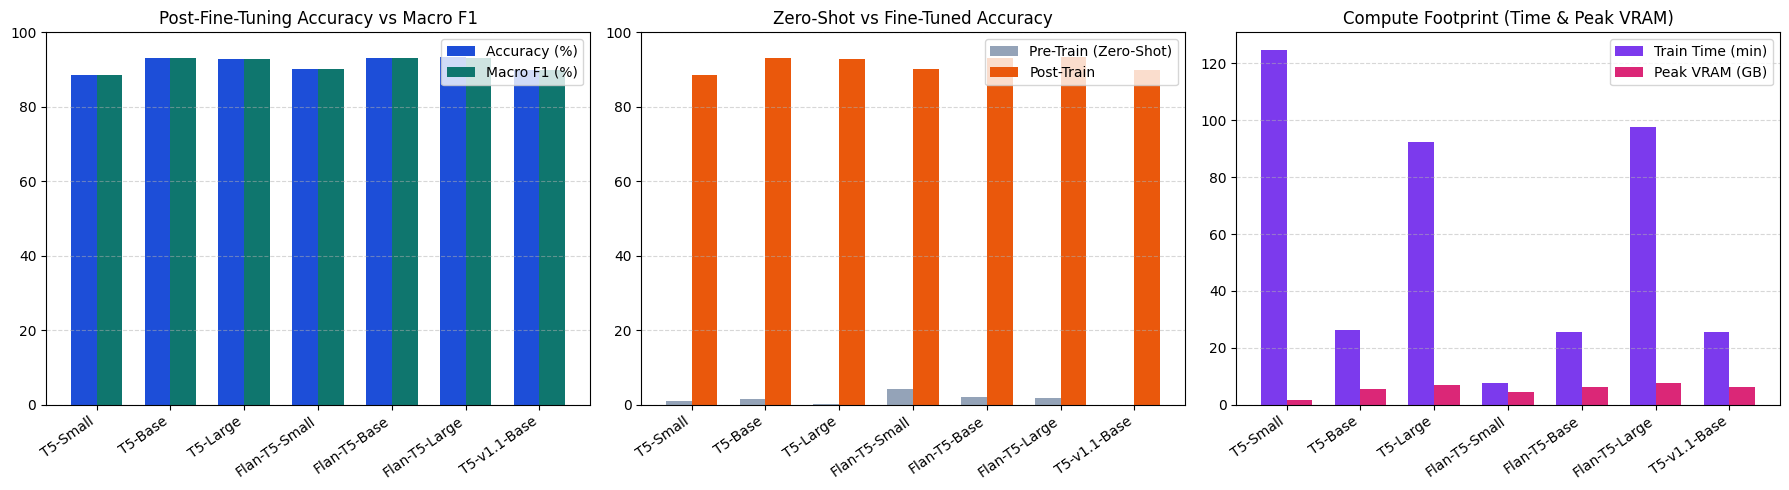

[SAVED] Chart saved to: /content/drive/MyDrive/NLP_Checkpoints/T5_training_Awais_Seed42/banking77_t5_comparison.png


In [ ]:
# --- 8. Final Benchmark Summary Table & Comparison Charts ---
benchmark_df = pd.DataFrame(results_records)
print("=" * 95)
print(f"FINAL BANKING77 T5 / FLAN-T5 BENCHMARK SUMMARY (Train: {len(train_texts):,} | Test: {len(test_texts):,})")
print("=" * 95)

display_cols = [
    "Model Name", "Pre-Train Accuracy (%)", "Post-Train Accuracy (%)", "Accuracy Gain (%)",
    "Post-Train Macro F1 (%)", "Exact Match Rate (%)", "Inference Latency (ms/query)",
    "Training Time (min)", "Peak VRAM Allocated (GB)", "Epochs"
]
print(benchmark_df[display_cols].to_markdown(index=False) if hasattr(benchmark_df, "to_markdown") else benchmark_df[display_cols])

plot_save_path = os.path.join(BASE_OUTPUT_DIR, "banking77_t5_comparison.png")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = np.arange(len(benchmark_df))
w = 0.35

axes[0].bar(x - w/2, benchmark_df["Post-Train Accuracy (%)"], w, label="Accuracy (%)", color="#1d4ed8")
axes[0].bar(x + w/2, benchmark_df["Post-Train Macro F1 (%)"], w, label="Macro F1 (%)", color="#0f766e")
axes[0].set_title("Post-Fine-Tuning Accuracy vs Macro F1")
axes[0].set_xticks(x)
axes[0].set_xticklabels(benchmark_df["Model Name"], rotation=35, ha="right")
axes[0].set_ylim(0, 100)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].bar(x - w/2, benchmark_df["Pre-Train Accuracy (%)"], w, label="Pre-Train (Zero-Shot)", color="#94a3b8")
axes[1].bar(x + w/2, benchmark_df["Post-Train Accuracy (%)"], w, label="Post-Train", color="#ea580c")
axes[1].set_title("Zero-Shot vs Fine-Tuned Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(benchmark_df["Model Name"], rotation=35, ha="right")
axes[1].set_ylim(0, 100)
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

axes[2].bar(x - w/2, benchmark_df["Training Time (min)"], w, label="Train Time (min)", color="#7c3aed")
axes[2].bar(x + w/2, benchmark_df["Peak VRAM Allocated (GB)"], w, label="Peak VRAM (GB)", color="#db2777")
axes[2].set_title("Compute Footprint (Time & Peak VRAM)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(benchmark_df["Model Name"], rotation=35, ha="right")
axes[2].legend()
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(plot_save_path, dpi=200)
plt.show()
print(f"[SAVED] Chart saved to: {plot_save_path}")

In [ ]:
# --- 9. Interactive Prediction Helper ---
def load_and_predict(query, model_save_name="Flan-T5-Base"):
    model_dir = os.path.join(BASE_OUTPUT_DIR, model_save_name)
    if not os.path.exists(model_dir):
        print(f"[ERROR] Checkpoint '{model_dir}' not found.")
        return
    tok = AutoTokenizer.from_pretrained(model_dir)
    mdl = AutoModelForSeq2SeqLM.from_pretrained(model_dir).to(device)
    mdl.eval()
    enc = tok(TASK_PREFIX + query, return_tensors="pt", truncation=True, max_length=MAX_SOURCE_LENGTH).to(device)
    with torch.no_grad():
        out = mdl.generate(**enc, max_new_tokens=MAX_TARGET_LENGTH, num_beams=1)
    gen_text = tok.decode(out[0], skip_special_tokens=True)
    pred_id, exact = parse_seq2seq_prediction(gen_text)
    print(f'Query: "{query}"')
    print(f"Raw Generated: '{gen_text}' | Canonical Intent: {id2label[pred_id] if pred_id != -1 else 'UNMAPPED'} (Exact: {exact})")
    del mdl, tok
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Example usage:
# load_and_predict("Can I transfer money directly using Apple Pay?", "Flan-T5-Base")